# Hands-On CP-SAT: O4A Hands-On Session

There is a solver out there that keeps winning OR challenges, and not enough people know about it: **CP-SAT** from Google OR-Tools.

In this notebook we
- write our **first CP-SAT model**: a small assignment problem, once in the style of a MIP and once with global constraints,
- then dive deep into **one** industrial problem from the [MiniZinc Challenge 2026](https://www.minizinc.org/challenge/2026/results/): **workforce allocation & scheduling**.

We don't model the workforce problem in one go. We slice the elephant: we start with a simple version and add requirements step by step. At every step we compare a straightforward, MIP-style formulation with the CP-SAT way of modeling it: **interval variables** and the global constraint `add_no_overlap`.

## Setup (Google Colab)

Run this cell to install the required packages. If you're running locally, you can skip this cell.

In [ ]:
# Install required packages (run this cell in Google Colab)
!pip install ortools==9.15.6755 pydantic matplotlib --quiet

In [2]:
# Imports
import json
import urllib.request
from itertools import combinations
from pathlib import Path
from typing import NewType

import matplotlib.pyplot as plt
from ortools.sat.python import cp_model
from pydantic import BaseModel, Field, model_validator

In [3]:
# Utility function for loading the challenge instances
# !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
# !!    You can skip this Code      !!
# !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

DATA_URL = "https://raw.githubusercontent.com/jpjj/O4A-Hands-On-CP-SAT/main/data"


def load_instance(problem: str, name: str) -> dict:
    """Load an instance from the local data folder or, e.g. in Colab, from GitHub."""
    local = Path("data") / problem / f"{name}.json"
    if local.exists():
        return json.loads(local.read_text())
    with urllib.request.urlopen(f"{DATA_URL}/{problem}/{name}.json") as response:
        return json.loads(response.read())

---
# Part 0: Hello CP-SAT

CP-SAT is **declarative**: we describe *what* a solution looks like (variables, constraints, objective), and the solver figures out *how* to find it.

Every CP-SAT program follows the same four steps:
1. Create a `CpModel`.
2. Add variables: `new_bool_var`, `new_int_var`, ...
3. Add constraints and, optionally, an objective.
4. Solve with a `CpSolver` and read the values.

All variables are **integers** or **Booleans**. CP-SAT has no continuous variables. If you have fractional data, scale it, e.g. work in minutes instead of hours.

## An Assignment Problem

Four workers, four jobs. Every worker does exactly one job, every job is done by exactly one worker, and each (worker, job) pair has a cost. Which assignment is the cheapest?

| Variable | Domain | Description |
|----------|--------|-------------|
| $x_{w,j}$ | $\{0,1\}$ | worker $w$ does job $j$ |

$$\min \sum_{w,j} c_{w,j} \, x_{w,j} \quad \text{s.t.} \quad \sum_j x_{w,j} = 1 \;\; \forall w, \qquad \sum_w x_{w,j} = 1 \;\; \forall j$$

If you have seen a MIP before, this looks familiar. In CP-SAT, we can write it down exactly like that.

In [4]:
workers = ["Ana", "Ben", "Chloe", "David"]
jobs = ["Excavation", "Concrete", "Wiring", "Painting"]
cost = [  # cost[w][j]: cost of worker w doing job j
    [90, 80, 75, 70],
    [35, 85, 55, 65],
    [125, 95, 90, 95],
    [45, 110, 95, 115],
]
W, J = range(len(workers)), range(len(jobs))

# 1. Create the model
model = cp_model.CpModel()

# 2. Variables: x[w, j] = 1 if worker w does job j
x = {(w, j): model.new_bool_var(f"x_{w}_{j}") for w in W for j in J}

# 3. Constraints and objective
for w in W:  # every worker does exactly one job
    model.add(sum(x[w, j] for j in J) == 1)
for j in J:  # every job is done by exactly one worker
    model.add(sum(x[w, j] for w in W) == 1)

model.minimize(sum(cost[w][j] * x[w, j] for w in W for j in J))

# 4. Solve and read the values
solver = cp_model.CpSolver()
status = solver.solve(model)

print(f"Status: {solver.status_name(status)}, total cost: {solver.objective_value:.0f}")
for w in W:
    for j in J:
        if solver.value(x[w, j]):
            print(f"  {workers[w]:6} -> {jobs[j]:10} ({cost[w][j]})")

Status: OPTIMAL, total cost: 265
  Ana    -> Painting   (70)
  Ben    -> Wiring     (55)
  Chloe  -> Concrete   (95)
  David  -> Excavation (45)


## The Same Problem, the CP-SAT Way

The MIP-style model talks about the problem *indirectly*, through 16 Booleans. CP-SAT lets us say what we actually mean:

- `job_of[w]` is an integer variable: **which** job does worker $w$ do?
- `add_all_different(job_of)`: no two workers do the same job. That's it, both families of constraints in one line.
- `add_element(index, values, target)` means `target == values[index]`: it looks up the cost of the chosen job.

`add_all_different` and `add_element` are **global constraints**: they capture a whole substructure of the problem, and the solver has specialized algorithms for each of them. The CP-SAT way of modeling is: find the structure in your problem, and use the global constraint that describes it.

In [5]:
model = cp_model.CpModel()

job_of = [model.new_int_var(0, len(jobs) - 1, f"job_of_{w}") for w in W]
cost_of = [model.new_int_var(0, max(cost[w]), f"cost_of_{w}") for w in W]

model.add_all_different(job_of)              # every job at most once
for w in W:
    model.add_element(job_of[w], cost[w], cost_of[w])  # cost_of[w] == cost[w][job_of[w]]

model.minimize(sum(cost_of))

solver = cp_model.CpSolver()
status = solver.solve(model)

print(f"Status: {solver.status_name(status)}, total cost: {solver.objective_value:.0f}")
for w in W:
    print(f"  {workers[w]:6} -> {jobs[solver.value(job_of[w])]}")

Status: OPTIMAL, total cost: 265
  Ana    -> Painting
  Ben    -> Wiring
  Chloe  -> Concrete
  David  -> Excavation


Same optimum, different model. For a problem this small, it doesn't matter which one we pick. Let's look at a problem where it matters a lot.

---
# Part 1: Workforce Allocation & Scheduling

## Problem Description

This problem comes from industry (Bleukx et al., *Modeling and explaining an industrial workforce allocation and scheduling problem*, CP 2025; [code](https://github.com/ML-KULeuven/Explainable-Workforce-Scheduling)) and was part of the MiniZinc Challenge 2026.

There are $N$ **teams** and $K$ **tasks**.

- Every task $j$ has a duration $d_j$ and a time window: it may start at its release time $r_j$ at the earliest and must end by its due date $\delta_j$. **We decide when exactly.**
- A task can only be done by a **compatible** team.
- A team does one task at a time and cannot work during its **unavailabilities** (calendar).
- **Precedences:** some tasks must be finished before others start.
- **Same team groups:** some tasks must be done by the same team.

**Objectives** (lexicographic):
1. Minimize the number of teams used.
2. Minimize the unfairness: the difference between the maximum and the minimum working time of the used teams.

## Slicing the Elephant

That's a lot at once. We build the model in four steps:

| Step | What we add | New modeling concept |
|------|-------------|----------------------|
| 1 | Assign tasks with **fixed start times** to compatible teams, minimize the number of teams | interval variables, `add_no_overlap` |
| 2 | **Time windows**: we decide the start times | enforcement literals |
| 3 | **Precedences, same team groups, unavailabilities** | fixed intervals |
| 4 | **Fairness** as a second objective | lexicographic objectives |

At steps 1 and 2 we write the model twice: first the MIP way, then the CP-SAT way.

## Domain Model

In [6]:
# Define Problem data structures

TeamId = NewType("TeamId", int)
TaskId = NewType("TaskId", int)


class TimeInterval(BaseModel, frozen=True):
    """A period of time [start, end)."""
    start: int = Field(ge=0)
    end: int

    @property
    def duration(self) -> int:
        return self.end - self.start

    @model_validator(mode="after")
    def check_order(self) -> "TimeInterval":
        if self.start >= self.end:
            raise ValueError(f"Interval [{self.start}, {self.end}) is empty")
        return self


class Team(BaseModel, frozen=True):
    """A team and the periods in which it cannot work."""
    id: TeamId
    unavailabilities: list[TimeInterval] = []


class Task(BaseModel, frozen=True):
    """A task that has to be done within its time window [release, due]."""
    id: TaskId
    release: int = Field(ge=0)
    due: int
    duration: int = Field(gt=0)
    compatible_teams: list[TeamId]

    @model_validator(mode="after")
    def check_window(self) -> "Task":
        if self.release + self.duration > self.due:
            raise ValueError(f"Task {self.id} does not fit into its time window")
        return self


class WorkforceProblem(BaseModel):
    """Represents the problem instance."""
    name: str = ""
    teams: list[Team]
    tasks: list[Task]
    precedence: list[tuple[TaskId, TaskId]] = []  # first task needs to finish before second task can start
    same_team: list[list[TaskId]] = []  # all tasks of a group are done by the same team

    @property
    def horizon(self) -> int:
        return max(t.due for t in self.tasks)

    @model_validator(mode="after")
    def check_feasible(self) -> "WorkforceProblem":
        team_ids = {team.id for team in self.teams}
        id_to_task = {task.id: task for task in self.tasks}
        if len(id_to_task) != len(self.tasks):
            raise ValueError("Task ids are not unique")
        for task in self.tasks:
            if not set(task.compatible_teams) <= team_ids:
                raise ValueError(f"Task {task.id} references an unknown team")
        for a, b in self.precedence:
            if a not in id_to_task or b not in id_to_task:
                raise ValueError(f"Precedence ({a}, {b}) references an unknown task")
            # both tasks have to fit into the time window of the second one, one after the other
            first, second = id_to_task[a], id_to_task[b]
            if first.release + first.duration + second.duration > second.due:
                raise ValueError(f"Precedence ({a}, {b}) can never be satisfied")
        for group in self.same_team:
            if not set(group) <= id_to_task.keys():
                raise ValueError(f"Group {group} references an unknown task")
        return self

    @classmethod
    def from_json(cls, data: dict) -> "WorkforceProblem":
        """Convert a challenge instance (see the data folder) into a WorkforceProblem."""
        teams = [
            Team(id=k, unavailabilities=[TimeInterval(start=u["start"], end=u["start"] + u["duration"])
                                         for u in data["unavailabilities"] if u["team"] == k])
            for k in range(data["num_teams"])
        ]
        return cls(name=data["name"], teams=teams, tasks=data["tasks"],
                   precedence=data["precedences"], same_team=data["same_team_groups"])

In [7]:
# Define Solution and helper functions
# !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
# !!    You can skip this Code      !!
# !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!


class WorkforceSolution(BaseModel):
    """A feasible solution: which team does which task when."""
    problem: WorkforceProblem
    assignment: dict[TaskId, TeamId]
    start_times: dict[TaskId, int]

    @property
    def worked(self) -> dict[TeamId, int]:
        """Working time per used team."""
        worked = {}
        for task in self.problem.tasks:
            team = self.assignment[task.id]
            worked[team] = worked.get(team, 0) + task.duration
        return worked

    @property
    def num_teams(self) -> int:
        return len(self.worked)

    @property
    def unfairness(self) -> int:
        return max(self.worked.values()) - min(self.worked.values())

    @property
    def cost(self) -> int:
        """Both objectives in one number (see step 4)."""
        total = sum(t.duration for t in self.problem.tasks)
        return total * self.num_teams + self.unfairness

    @model_validator(mode="after")
    def check_feasible(self) -> "WorkforceSolution":
        p = self.problem
        tasks = {t.id: t for t in p.tasks}
        if self.assignment.keys() != tasks.keys() or self.start_times.keys() != tasks.keys():
            raise ValueError("Every task needs exactly one team and one start time")
        end = {j: self.start_times[j] + t.duration for j, t in tasks.items()}
        for j, task in tasks.items():
            if self.assignment[j] not in task.compatible_teams:
                raise ValueError(f"Task {j} is assigned to an incompatible team")
            if self.start_times[j] < task.release or end[j] > task.due:
                raise ValueError(f"Task {j} violates its time window")
        for a, b in p.precedence:
            if end[a] > self.start_times[b]:
                raise ValueError(f"Precedence {a} -> {b} is violated")
        for group in p.same_team:
            if len({self.assignment[j] for j in group}) > 1:
                raise ValueError(f"Group {group} is split over several teams")
        for team in p.teams:
            busy = sorted([(self.start_times[j], end[j]) for j in tasks if self.assignment[j] == team.id]
                          + [(u.start, u.end) for u in team.unavailabilities])
            for (_, busy_until), (next_start, _) in zip(busy, busy[1:]):
                if next_start < busy_until:
                    raise ValueError(f"Team {team.id} is busy twice at time {next_start}")
        return self


def plot_solution(solution: WorkforceSolution, title: str | None = None):
    """Plot a Gantt chart with one row per used team."""
    p = solution.problem
    used = sorted(solution.worked)
    fig, ax = plt.subplots(figsize=(14, max(2, 0.6 * len(used) + 1)))
    for row, team in enumerate(used):
        for u in p.teams[team].unavailabilities:
            ax.barh(row, u.duration, left=u.start, height=0.5, color="grey", alpha=0.3,
                    hatch="//", edgecolor="grey")
        for task in p.tasks:
            if solution.assignment[task.id] == team:
                start = solution.start_times[task.id]
                ax.barh(row, task.duration, left=start, height=0.5, color="steelblue",
                        edgecolor="darkblue", linewidth=1)
                ax.text(start + task.duration / 2, row, str(task.id), ha="center", va="center",
                        color="white", fontweight="bold", fontsize=8)
    ax.set_yticks(range(len(used)))
    ax.set_yticklabels([f"Team {k} ({solution.worked[k]})" for k in used])
    ax.invert_yaxis()
    ax.set_xlim(0, p.horizon)
    ax.set_xlabel("Time")
    ax.set_title(title or f"{p.name}: {solution.num_teams} teams, unfairness {solution.unfairness}")
    ax.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()


def solve(problem: WorkforceProblem, create_model, time_limit: float = 30, verbose: bool = False,
          **kwargs) -> WorkforceSolution | None:
    """Build the model with create_model(problem, **kwargs), solve it and return a validated solution."""
    model, x, start = create_model(problem, **kwargs)
    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = time_limit
    solver.parameters.log_search_progress = verbose
    status = solver.solve(model)
    if status not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        print(f"{problem.name}: {solver.status_name(status)} after {solver.wall_time:.2f}s")
        return None
    print(f"{problem.name}: {solver.status_name(status)} after {solver.wall_time:.2f}s, "
          f"objective {solver.objective_value:.0f}, bound {solver.best_objective_bound:.0f}")
    return WorkforceSolution(
        problem=problem,
        assignment={j: k for (j, k), lit in x.items() if solver.boolean_value(lit)},
        start_times={t.id: solver.value(start[t.id]) for t in problem.tasks},
    )


def print_model_size(model: cp_model.CpModel):
    proto = model.proto
    print(f"{len(proto.variables):6} variables, {len(proto.constraints):6} constraints")

---
## Step 1: Who Does What?

We start with the core of the problem: **assigning** tasks to teams. For now, every task has a **fixed start time**: its time window is exactly as long as the task ($\delta_j = r_j + d_j$). The only decision is which team does which task, and we want to use as few teams as possible.

Our baby example: three teams, six tasks, a working day of 8 hours.

In [8]:
baby_1 = WorkforceProblem(
    name="baby_1",
    teams=[Team(id=0), Team(id=1), Team(id=2)],
    tasks=[  # release + duration == due: the start times are fixed
        Task(id=0, release=0, due=2, duration=2, compatible_teams=[0, 1, 2]),
        Task(id=1, release=0, due=3, duration=3, compatible_teams=[0, 1]),
        Task(id=2, release=3, due=5, duration=2, compatible_teams=[0, 1, 2]),
        Task(id=3, release=6, due=7, duration=1, compatible_teams=[1, 2]),
        Task(id=4, release=1, due=3, duration=2, compatible_teams=[0, 1, 2]),
        Task(id=5, release=5, due=7, duration=2, compatible_teams=[0, 2]),
    ],
)

### The MIP Way

| Variable | Domain | Description |
|----------|--------|-------------|
| $x_{j,k}$ | $\{0,1\}$ | team $k$ does task $j$ (only for compatible pairs) |
| $used_k$ | $\{0,1\}$ | team $k$ does at least one task |

- Every task is done by exactly one compatible team: $\sum_k x_{j,k} = 1$.
- A team that does a task is used: $x_{j,k} \leq used_k$.
- A team does one task at a time: for every pair of tasks $(a, b)$ that **overlap in time** and every team $k$ that could do both: $x_{a,k} + x_{b,k} \leq 1$.
- Objective: $\min \sum_k used_k$.

The assignment part stays the same in all steps, so we put it into its own function. `add_exactly_one` is a shortcut for `sum(...) == 1`, and `add_implication(a, b)` means $a \Rightarrow b$.

In [9]:
def add_assignment(model: cp_model.CpModel, problem: WorkforceProblem):
    """x[j, k]: team k does task j. used[k]: team k does at least one task."""
    x = {(t.id, k): model.new_bool_var(f"x_{t.id}_{k}") for t in problem.tasks for k in t.compatible_teams}
    used = {team.id: model.new_bool_var(f"used_{team.id}") for team in problem.teams}

    for t in problem.tasks:  # every task is done by exactly one compatible team
        model.add_exactly_one(x[t.id, k] for k in t.compatible_teams)

    for team in problem.teams:  # a team is used if and only if it does at least one task
        assigned = [x[t.id, team.id] for t in problem.tasks if team.id in t.compatible_teams]
        for lit in assigned:
            model.add_implication(lit, used[team.id])
        model.add_bool_or(assigned).only_enforce_if(used[team.id])
    return x, used


def add_no_overlap_pairwise_fixed(model: cp_model.CpModel, problem: WorkforceProblem, x):
    """MIP way: two tasks that overlap in time cannot be done by the same team."""
    for a, b in combinations(problem.tasks, 2):
        if a.release < b.due and b.release < a.due:  # the (fixed) times overlap
            for k in set(a.compatible_teams) & set(b.compatible_teams):
                model.add(x[a.id, k] + x[b.id, k] <= 1)

### The CP-SAT Way: Interval Variables

The pairwise constraints work, but they are a decomposition: the solver sees thousands of small, unrelated constraints instead of the structure behind them, *"each team has a timeline, and its tasks must not overlap on it"*.

CP-SAT has a dedicated variable type for scheduling: the **interval variable**. An interval consists of
- a start $s$, a size $d$ and an end $e$ with $s + d = e$,
- and optionally a **presence literal**: an *optional interval* only exists if its literal is true.

We create one optional interval per compatible (task, team) pair, present iff $x_{j,k}$. Then one global constraint per team does the job:

`model.add_no_overlap(intervals of team k)`

Only present intervals take part. No pairs, no ordering decisions.

Note that `start` is a parameter: right now we pass the fixed start times (plain integers). Keep that in mind for step 2.

In [10]:
def add_no_overlap_intervals(model: cp_model.CpModel, problem: WorkforceProblem, x, start):
    """CP-SAT way: one optional interval per (task, team), present iff x[task, team]. No overlap per team."""
    for team in problem.teams:
        intervals = [
            model.new_optional_fixed_size_interval_var(start[t.id], t.duration, x[t.id, team.id], f"task_{t.id}_team_{team.id}")
            for t in problem.tasks
            if team.id in t.compatible_teams
        ]
        model.add_no_overlap(intervals)

MIP way:
baby_1: OPTIMAL after 0.00s, objective 3, bound 3
CP-SAT way:
baby_1: OPTIMAL after 0.00s, objective 3, bound 3


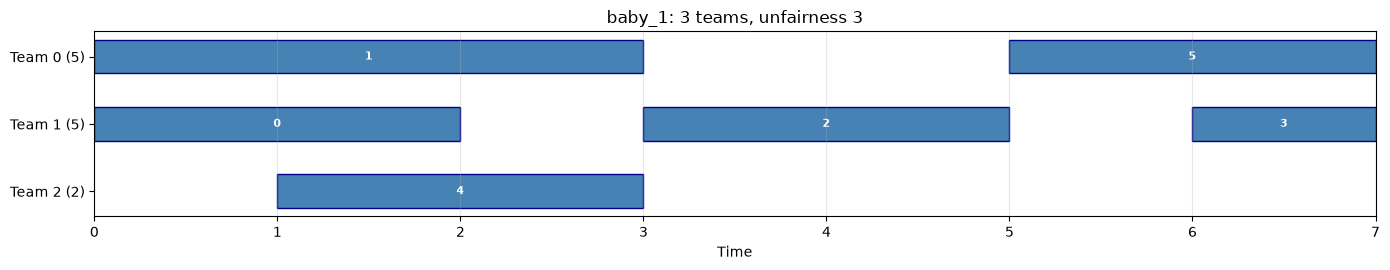

In [11]:
def create_model_step1(problem: WorkforceProblem, pairwise: bool = False):
    model = cp_model.CpModel()
    x, used = add_assignment(model, problem)
    start = {t.id: t.release for t in problem.tasks}  # fixed start times
    if pairwise:
        add_no_overlap_pairwise_fixed(model, problem, x)
    else:
        add_no_overlap_intervals(model, problem, x, start)
    model.minimize(sum(used.values()))
    return model, x, start


for pairwise in [True, False]:
    print("MIP way:" if pairwise else "CP-SAT way:")
    solution_1 = solve(baby_1, create_model_step1, pairwise=pairwise)
plot_solution(solution_1)

Both models agree: with fixed start times, we need **three teams**. Look at time 1 to 2: tasks 0, 1 and 4 run at the same time.

<div style="background-color: #2195f33c; border: 2px solid #2196F3; border-radius: 8px; padding: 16px; margin: 16px 0;">

# **🗣️ BREAKOUT SESSION 1**

In reality, tasks are not fixed in time: a customer gives us a **time window** and we decide when the task starts.

- What changes in the MIP-way model? Which new variables and constraints do you need? How many?
- What changes in the CP-SAT-way model?
- Do you think we can save a team in the baby example?

</div>

---
## Step 2: When? Time Windows

Now every task gets a real time window, and its start time becomes a variable:

| Variable | Domain | Description |
|----------|--------|-------------|
| $start_j$ | $\{r_j, \dots, \delta_j - d_j\}$ | start time of task $j$ |

Note the **tight domain**: the time window is part of the variable's domain, no extra constraints needed.

In [12]:
baby_2 = WorkforceProblem(
    name="baby_2",
    teams=[Team(id=0), Team(id=1), Team(id=2)],
    tasks=[
        Task(id=0, release=0, due=4, duration=2, compatible_teams=[0, 1, 2]),
        Task(id=1, release=0, due=8, duration=3, compatible_teams=[0, 1]),
        Task(id=2, release=2, due=6, duration=2, compatible_teams=[0, 1, 2]),
        Task(id=3, release=5, due=8, duration=1, compatible_teams=[1, 2]),
        Task(id=4, release=0, due=8, duration=2, compatible_teams=[0, 1, 2]),
        Task(id=5, release=4, due=8, duration=2, compatible_teams=[0, 2]),
    ],
)


def add_start_times(model: cp_model.CpModel, problem: WorkforceProblem):
    return {t.id: model.new_int_var(t.release, t.due - t.duration, f"start_{t.id}") for t in problem.tasks}

### The MIP Way: Ordering Decisions

If two tasks $a$ and $b$ are done by the same team, one of them has to come first. We need a new Boolean $before_{a,b}$ for every pair of tasks whose time windows overlap, and for every team $k$ that could do both:

$$x_{a,k} \land x_{b,k} \land before_{a,b} \;\Rightarrow\; start_a + d_a \leq start_b$$
$$x_{a,k} \land x_{b,k} \land \lnot before_{a,b} \;\Rightarrow\; start_b + d_b \leq start_a$$

In a MIP, these implications become **Big-M constraints**, e.g. $start_a + d_a \leq start_b + M (3 - x_{a,k} - x_{b,k} - before_{a,b})$, and you have to choose a good $M$.

In CP-SAT, we write the implication directly with an **enforcement literal**: `model.add(constraint).only_enforce_if(literals)`. The constraint is only active if all literals are true. There is no $M$ to choose, and the solver reasons about the implication directly.

In [13]:
def add_no_overlap_pairwise(model: cp_model.CpModel, problem: WorkforceProblem, x, start):
    """MIP way: if two tasks are done by the same team, one of them comes first."""
    for a, b in combinations(problem.tasks, 2):
        if a.release < b.due and b.release < a.due:  # the time windows overlap
            a_first = model.new_bool_var(f"{a.id}_before_{b.id}")
            for k in set(a.compatible_teams) & set(b.compatible_teams):
                model.add(start[a.id] + a.duration <= start[b.id]).only_enforce_if(x[a.id, k], x[b.id, k], a_first)
                model.add(start[b.id] + b.duration <= start[a.id]).only_enforce_if(x[a.id, k], x[b.id, k], ~a_first)

### The CP-SAT Way: Nothing to Do

Our function `add_no_overlap_intervals` already takes `start` as a parameter. We simply pass the start time **variables** instead of fixed numbers, and the intervals move along. The model is exactly the same as in step 1.

MIP way:
baby_2: OPTIMAL after 0.01s, objective 2, bound 2
CP-SAT way:
baby_2: OPTIMAL after 0.00s, objective 2, bound 2


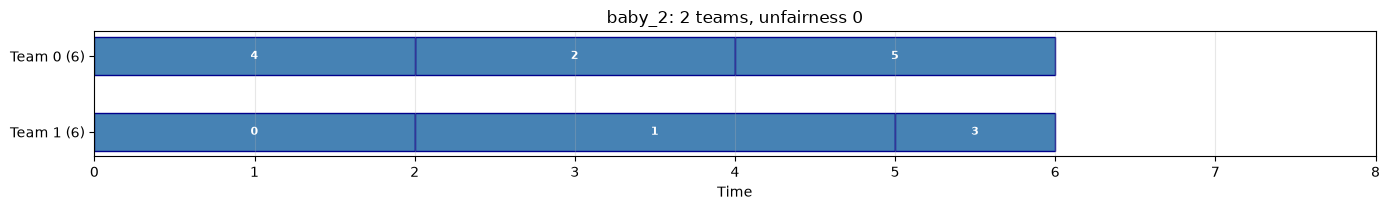

In [14]:
def create_model_step2(problem: WorkforceProblem, pairwise: bool = False):
    model = cp_model.CpModel()
    x, used = add_assignment(model, problem)
    start = add_start_times(model, problem)  # NEW: variables instead of fixed start times
    if pairwise:
        add_no_overlap_pairwise(model, problem, x, start)
    else:
        add_no_overlap_intervals(model, problem, x, start)
    model.minimize(sum(used.values()))
    return model, x, start


for pairwise in [True, False]:
    print("MIP way:" if pairwise else "CP-SAT way:")
    solution_2 = solve(baby_2, create_model_step2, pairwise=pairwise)
plot_solution(solution_2)

The flexibility saves a team: **two teams** are enough now.

How big do both models get on a real instance? Let's build them for a challenge instance with 58 tasks and 18 teams (we only build them here; we solve the full problem at the end).

In [15]:
problem_71 = WorkforceProblem.from_json(load_instance("workforce", "instance_71"))

for pairwise in [True, False]:
    model, _, _ = create_model_step2(problem_71, pairwise=pairwise)
    print("MIP way:   " if pairwise else "CP-SAT way:", end=" ")
    print_model_size(model)

MIP way:      1725 variables,  22740 constraints
CP-SAT way:   1088 variables,   2118 constraints


The MIP way grows with the number of **pairs of tasks times teams**, the CP-SAT way with the number of **compatible (task, team) pairs**. (Interval variables count as constraints in CP-SAT's internal model.)

From here on, we continue with the CP-SAT way only.

---
## Step 3: The Real World Strikes Back

Three more requirements:

- **Unavailabilities:** team 0 has a lunch break from 4:00 to 5:00. A lunch break is just an interval that is always there: a **fixed interval** (`new_fixed_size_interval_var`). We add it to the team's `add_no_overlap`, and tasks can no longer overlap with it. One new line.
- **Precedences** $(a, b)$: task $a$ ends before task $b$ starts: $start_a + d_a \leq start_b$.
- **Same team groups:** all tasks of a group are done by the same team: $x_{a,k} = x_{b,k}$ for all teams $k$. If only one of the two tasks is compatible with team $k$, the other one can't be done by $k$ either.

In [16]:
baby_3 = WorkforceProblem(
    name="baby_3",
    teams=[Team(id=0, unavailabilities=[TimeInterval(start=4, end=5)]), Team(id=1), Team(id=2)],  # NEW: lunch break
    tasks=baby_2.tasks,
    precedence=[(0, 2)],  # NEW: task 0 before task 2
    same_team=[[3, 5]],   # NEW: tasks 3 and 5 are done by the same team
)


def add_no_overlap_intervals(model: cp_model.CpModel, problem: WorkforceProblem, x, start):
    """CP-SAT way: one optional interval per (task, team), present iff x[task, team]. No overlap per team."""
    for team in problem.teams:
        intervals = [
            model.new_optional_fixed_size_interval_var(start[t.id], t.duration, x[t.id, team.id], f"task_{t.id}_team_{team.id}")
            for t in problem.tasks
            if team.id in t.compatible_teams
        ]
        # NEW: unavailabilities are intervals that are always present
        intervals += [model.new_fixed_size_interval_var(u.start, u.duration, f"off_{team.id}_{u.start}")
                      for u in team.unavailabilities]
        model.add_no_overlap(intervals)

In [17]:
def add_precedence_and_same_team(model: cp_model.CpModel, problem: WorkforceProblem, x, start):
    duration = {t.id: t.duration for t in problem.tasks}

    # Precedences: task a ends before task b starts
    for a, b in problem.precedence:
        model.add(start[a] + duration[a] <= start[b])

    # Same team groups: compare every task of a group with the first one
    for first, *others in problem.same_team:
        for other in others:
            for team in problem.teams:
                k = team.id
                if (first, k) in x or (other, k) in x:
                    model.add(x.get((first, k), 0) == x.get((other, k), 0))

baby_3: OPTIMAL after 0.00s, objective 2, bound 2


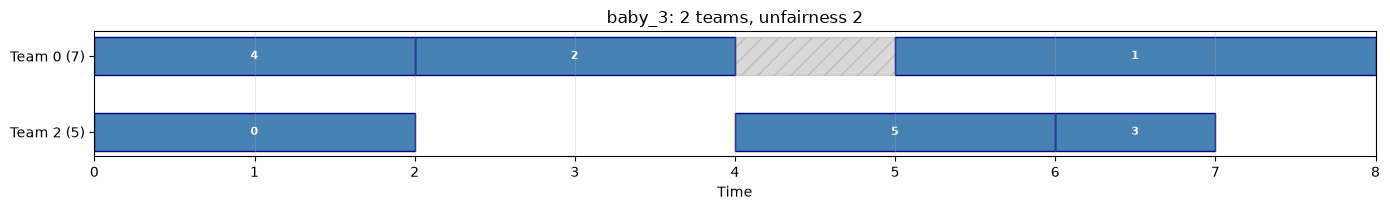

In [18]:
def create_model_step3(problem: WorkforceProblem):
    model = cp_model.CpModel()
    x, used = add_assignment(model, problem)
    start = add_start_times(model, problem)
    add_no_overlap_intervals(model, problem, x, start)
    add_precedence_and_same_team(model, problem, x, start)  # NEW
    model.minimize(sum(used.values()))
    return model, x, start


solution_3 = solve(baby_3, create_model_step3)
plot_solution(solution_3)

Still two teams, despite the lunch break. But nobody told the solver to share the work fairly: whatever balance you see in the chart is pure luck.

<div style="background-color: #2195f33c; border: 2px solid #2196F3; border-radius: 8px; padding: 16px; margin: 16px 0;">

# **🗣️ BREAKOUT SESSION 2**

Now we want to add the second objective: **fairness**, the difference between the maximum and the minimum working time of the **used** teams. The number of teams still comes first.

- How do you model the maximum and the minimum working time? Why is the minimum harder than the maximum?
- How do you combine two objectives into one, so that saving a team always beats fairness?

</div>

---
## Step 4: Fair Is Fair

The working time of team $k$ is linear in our variables: $worked_k = \sum_j d_j \, x_{j,k}$.

| Variable | Domain | Description |
|----------|--------|-------------|
| $max$ | $\{0, \dots, \sum_j d_j\}$ | maximum working time |
| $min$ | $\{0, \dots, \sum_j d_j\}$ | minimum working time of the **used** teams |

- $max \geq worked_k$ for all teams $k$. Unused teams work 0, so they never matter here.
- $min \leq worked_k$ **only if** team $k$ is used: `.only_enforce_if(used[k])`. Without the enforcement literal, an unused team would pull the minimum down to 0.

**Lexicographic objective:** the unfairness $max - min$ is always smaller than the total duration $\sum_j d_j$. If we weight the number of teams with $\sum_j d_j$, saving one team is always worth more than any improvement in fairness:

$$\min \; \Big(\sum_j d_j\Big) \cdot \sum_k used_k + (max - min)$$

In [19]:
def add_fairness(model: cp_model.CpModel, problem: WorkforceProblem, x, used):
    """Return the working time per team and the unfairness (max - min working time of the used teams)."""
    total = sum(t.duration for t in problem.tasks)
    worked = {team.id: sum(t.duration * x[t.id, team.id] for t in problem.tasks if team.id in t.compatible_teams)
              for team in problem.teams}
    max_worked = model.new_int_var(0, total, "max_worked")
    min_worked = model.new_int_var(0, total, "min_worked")
    for k in worked:
        model.add(max_worked >= worked[k])
        model.add(min_worked <= worked[k]).only_enforce_if(used[k])
    return worked, max_worked - min_worked

baby_3: OPTIMAL after 0.01s, objective 26, bound 26


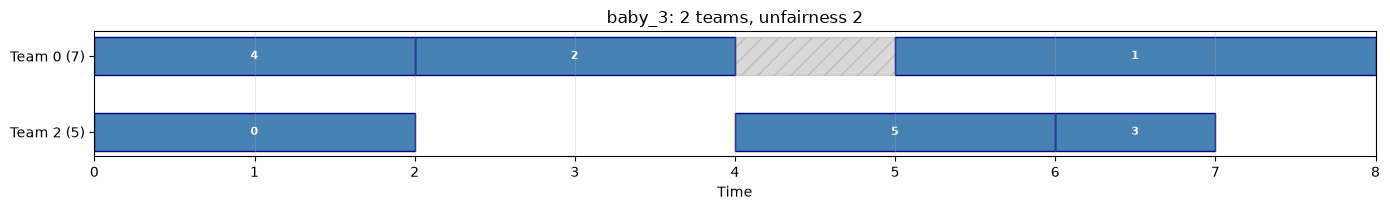

In [20]:
def create_model(problem: WorkforceProblem, pairwise: bool = False, symmetry_breaking: bool = False):
    """The full model. pairwise=True uses the MIP way for the no-overlap part."""
    model = cp_model.CpModel()
    total = sum(t.duration for t in problem.tasks)
    x, used = add_assignment(model, problem)
    start = add_start_times(model, problem)
    if pairwise:
        add_no_overlap_pairwise(model, problem, x, start)  # ignores unavailabilities, the challenge instances have none
    else:
        add_no_overlap_intervals(model, problem, x, start)
    add_precedence_and_same_team(model, problem, x, start)
    worked, unfairness = add_fairness(model, problem, x, used)  # NEW
    if symmetry_breaking:
        add_team_symmetry_breaking(model, problem, used, worked)  # see "Break Symmetries" below
    model.minimize(total * sum(used.values()) + unfairness)  # NEW: lexicographic objective
    return model, x, start


solution_4 = solve(baby_3, create_model)
plot_solution(solution_4)

The optimum: 2 teams with 12 hours of work in total, and an unfairness of 2, so $12 \cdot 2 + 2 = 26$. Can you see why a perfect 6/6 split is impossible? (Hint: tasks 3 and 5.)

## A Challenge Instance (58 tasks, 18 teams)

Time for the real thing. Let's give the solver 20 seconds.

58 tasks, 18 teams, 25 precedences, 8 same team groups


instance_71: OPTIMAL after 9.91s, objective 10125, bound 10125


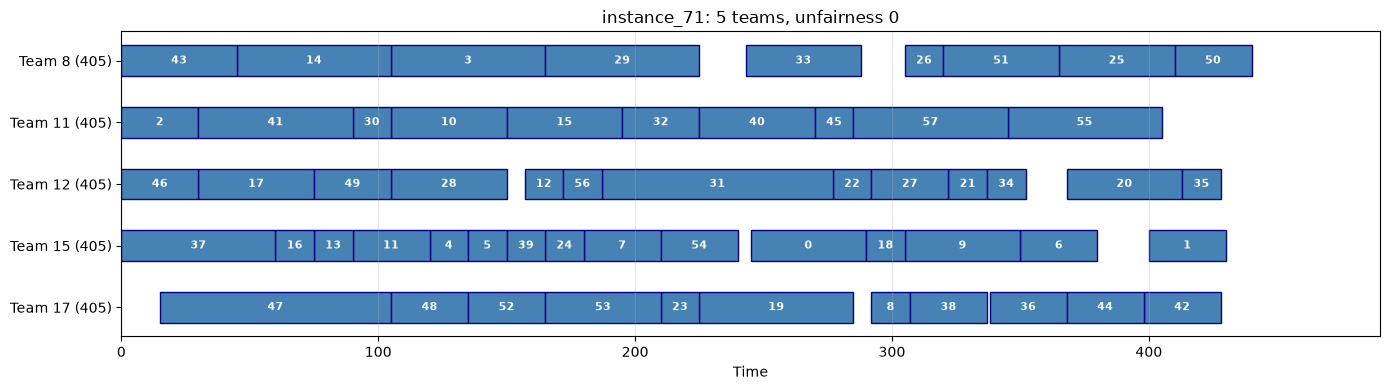

In [21]:
print(f"{len(problem_71.tasks)} tasks, {len(problem_71.teams)} teams, "
      f"{len(problem_71.precedence)} precedences, {len(problem_71.same_team)} same team groups")

solution_71 = solve(problem_71, create_model, time_limit=20)
plot_solution(solution_71)

CP-SAT finds a great solution quickly. **Proving** that it is optimal is much harder: with the two cores of a free Colab instance, the bound stays far below the objective after 20 seconds. On a laptop with many cores it takes several seconds.

## Best Practice: Break Symmetries

Most teams in this instance are interchangeable: they can do the same tasks and have the same calendar. A solution with 5 teams can be relabeled in $18 \cdot 17 \cdot 16 \cdot 15 \cdot 14 > 1{,}000{,}000$ ways, and the solver has to rule out every one of them to prove optimality.

We tell the solver to use interchangeable teams in a fixed order: team $k_2$ may only be used if team $k_1 < k_2$ is used, and it works at most as long as $k_1$.

instance_71: OPTIMAL after 0.91s, objective 10125, bound 10125


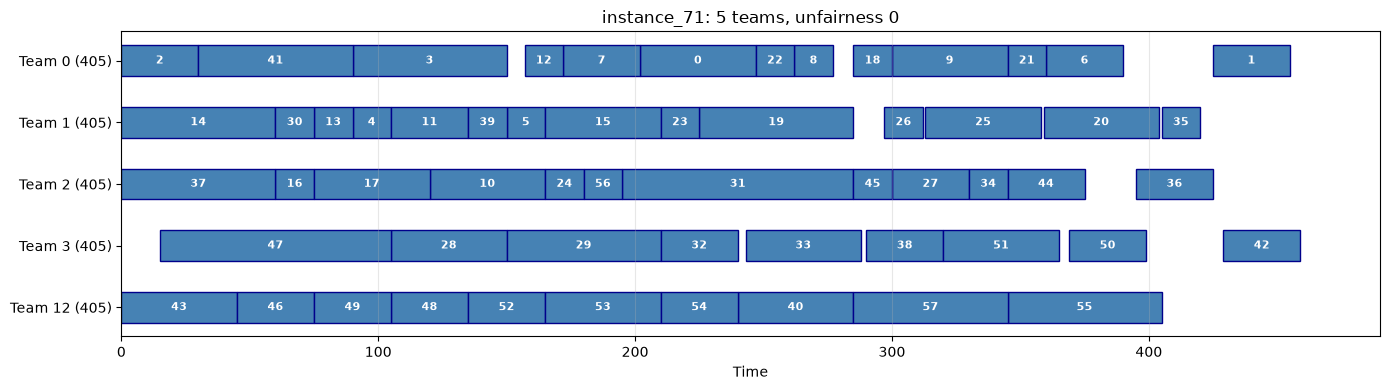

In [22]:
def add_team_symmetry_breaking(model: cp_model.CpModel, problem: WorkforceProblem, used, worked):
    """Teams with the same compatible tasks and the same calendar are interchangeable.
    Use them in order and sort them by working time."""
    groups = {}
    for team in problem.teams:
        tasks_k = tuple(t.id for t in problem.tasks if team.id in t.compatible_teams)
        groups.setdefault((tasks_k, tuple(team.unavailabilities)), []).append(team.id)
    for group in groups.values():
        for k1, k2 in zip(group, group[1:]):
            model.add(used[k1] >= used[k2])
            model.add(worked[k1] >= worked[k2])


solution_71 = solve(problem_71, create_model, time_limit=20, symmetry_breaking=True)
plot_solution(solution_71)

**Optimal** in a fraction of a second: 5 teams, perfectly fair (405 each).

## Does the Global Constraint Pay Off?

Finally, let's compare the MIP way and the CP-SAT way on four challenge instances: same solver, same constraints, same symmetry breaking, 30 seconds each. The only difference is how we model "one task at a time". This takes a few minutes.

In [23]:
rows = []
for name in ["instance_202", "instance_24_56", "instance_71", "instance_19"]:
    problem = WorkforceProblem.from_json(load_instance("workforce", name))
    for pairwise in [True, False]:
        model, _, _ = create_model(problem, pairwise=pairwise, symmetry_breaking=True)
        solver = cp_model.CpSolver()
        solver.parameters.max_time_in_seconds = 30
        status = solver.solve(model)
        rows.append((name, "MIP way" if pairwise else "CP-SAT way", len(model.proto.constraints),
                     solver.status_name(status), solver.objective_value, solver.best_objective_bound, solver.wall_time))

print(f"{'instance':15} {'model':10} {'constraints':>11} {'status':>9} {'objective':>9} {'bound':>7} {'time':>6}")
for name, way, size, status, objective, bound, time in rows:
    print(f"{name:15} {way:10} {size:11} {status:>9} {objective:9.0f} {bound:7.0f} {time:5.1f}s")

instance        model      constraints    status objective   bound   time
instance_202    MIP way           5261   OPTIMAL      1125    1125   0.4s
instance_202    CP-SAT way        1175   OPTIMAL      1125    1125   0.1s
instance_24_56  MIP way           4431   OPTIMAL      1425    1425   0.2s
instance_24_56  CP-SAT way        1083   OPTIMAL      1425    1425   0.1s
instance_71     MIP way          23013   OPTIMAL     10125   10125   6.2s
instance_71     CP-SAT way        2391   OPTIMAL     10125   10125   1.1s
instance_19     MIP way          33501  FEASIBLE      9000    7200  30.0s
instance_19     CP-SAT way        2931   OPTIMAL      9000    9000   0.5s


### Takeaways

- **Slice the elephant.** Start with the core of the problem and add requirements one by one. Check every step on a baby example.
- Interval variables and `add_no_overlap` replace a quadratic number of ordering variables and constraints.
- Optional intervals combine *assignment* (which team?) and *scheduling* (when?) in one variable. Moving from fixed to flexible start times did not change the model at all.
- Enforcement literals (`only_enforce_if`) replace Big-M constraints.
- **Break symmetries.** Interchangeable resources blow up the search space, for CP-SAT and for MIP solvers alike.

---
# Key Takeaways

## When to use CP-SAT, when to use MIP?

| CP-SAT shines | MIP shines |
|---------------|------------|
| Scheduling with disjunctions: intervals, no-overlap, calendars | Strong LP relaxations, e.g. flows, network design |
| Logical and combinatorial constraints, pure feasibility | Continuous variables, huge linear models |
| Routing with side constraints (`add_circuit`) | Facility location, classic TSP formulations |
| Small to medium integer domains | Very large numbers, fractional data |

In the MiniZinc Challenge 2026, MIP solvers won on problems like warehouse location and TSP-like problems. **Know both tools.** CP-SAT itself also contains an LP relaxation, so it brings a bit of both worlds.

## Best practices for scalable CP-SAT models

1. **Tight domains** for every integer variable (e.g. start times within the task's time window).
2. **Enforcement literals** (`only_enforce_if`) instead of Big-M constraints.
3. **Global constraints** (`add_all_different`, `add_element`, `add_no_overlap`, `add_circuit`, ...) instead of hand-made decompositions.
4. **Break symmetries** and add **dominance rules**.
5. **Booleans** over integer "labels" where possible.
6. **Use all cores** (`num_workers`, by default all available) and read the log (`log_search_progress = True`).
7. Integers only: **scale** fractional data.

## Further Resources

- [The CP-SAT Primer](https://d-krupke.github.io/cpsat-primer/) by Dominik Krupke: the best guide to CP-SAT
- [OR-Tools documentation](https://developers.google.com/optimization/cp)
- [CP-SAT masterclass at CPAIOR 2020](https://www.youtube.com/watch?v=lmy1ddn4cyw) by Laurent Perron and Frédéric Didier: how CP-SAT works inside
- [MiniZinc Challenge 2026 results](https://www.minizinc.org/challenge/2026/results/)

---
# Thank You!

Questions?

**Let's connect on LinkedIn:** [Jens-Peter Joost](https://www.linkedin.com/in/jens-peter-joost/)

**More O4A hands-on sessions:** [Optimization4All on YouTube](https://www.youtube.com/@Optimization4All/playlists)